---
title: "Gradient Descent Explained: The Engine Behind Machine Learning"
author: "Fabian"
date: "2024-02-12"
categories: [NLP]
format:
  html:
    code-fold: false
    toc: true
    echo: true
jupyter: python3
freeze: true

---

## 1. What is Gradient Descent?

Gradient Descent is an **optimization algorithm** used to find the minimum of a function.

* Imagine you’re standing on a hill (a function curve).
* You want to reach the bottom (the minimum).
* At each step, you look at the **slope** (the gradient) of the hill and move **downhill** a little.
* The **learning rate** controls how big each step is.
* You keep repeating until you’re close enough to the bottom.

## 2. The Math Idea

Suppose we have a function $f(x)$.
The update rule for $x$ is:

$$
x_{\text{new}} = x_{\text{old}} - \eta \cdot f'(x_{\text{old}})
$$

* $f'(x)$ = derivative (gradient)
* $\eta$ = learning rate (step size)

For multiple variables (like in machine learning models), you just apply this rule for each parameter.


## 3. Python Example – Gradient Descent on a Simple Function

Let’s minimize:

$$
f(x) = x^2
$$

Its derivative is:

$$
f'(x) = 2x
$$

Iteration 1: x = 8.0000, f(x) = 64.0000
Iteration 2: x = 6.4000, f(x) = 40.9600
Iteration 3: x = 5.1200, f(x) = 26.2144
Iteration 4: x = 4.0960, f(x) = 16.7772
Iteration 5: x = 3.2768, f(x) = 10.7374
Iteration 6: x = 2.6214, f(x) = 6.8719
Iteration 7: x = 2.0972, f(x) = 4.3980
Iteration 8: x = 1.6777, f(x) = 2.8147
Iteration 9: x = 1.3422, f(x) = 1.8014
Iteration 10: x = 1.0737, f(x) = 1.1529
Iteration 11: x = 0.8590, f(x) = 0.7379
Iteration 12: x = 0.6872, f(x) = 0.4722
Iteration 13: x = 0.5498, f(x) = 0.3022
Iteration 14: x = 0.4398, f(x) = 0.1934
Iteration 15: x = 0.3518, f(x) = 0.1238
Iteration 16: x = 0.2815, f(x) = 0.0792
Iteration 17: x = 0.2252, f(x) = 0.0507
Iteration 18: x = 0.1801, f(x) = 0.0325
Iteration 19: x = 0.1441, f(x) = 0.0208
Iteration 20: x = 0.1153, f(x) = 0.0133


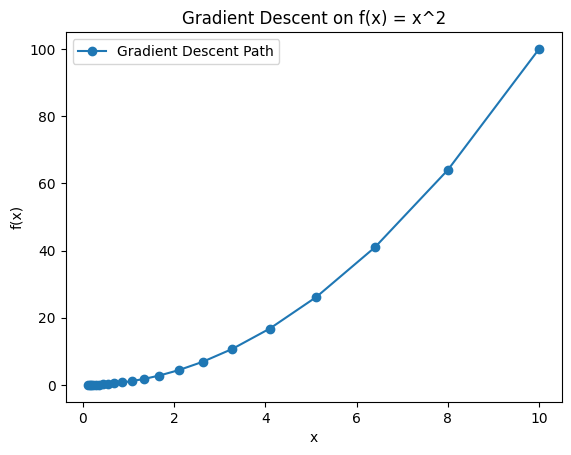

In [1]:
import matplotlib.pyplot as plt

# Function and derivative
def f(x):
    return x**2

def f_prime(x):
    return 2*x

# Gradient descent parameters
x = 10          # start point
learning_rate = 0.1
iterations = 20

history = [x]  # to track progress

# Gradient descent loop
for i in range(iterations):
    gradient = f_prime(x)
    x = x - learning_rate * gradient
    history.append(x)
    print(f"Iteration {i+1}: x = {x:.4f}, f(x) = {f(x):.4f}")

# Plot the path
xs = [i for i in history]
ys = [f(val) for val in history]

plt.plot(xs, ys, "o-", label="Gradient Descent Path")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent on f(x) = x^2")
plt.legend()
plt.show()

## 4. Output

* The `x` values will keep moving closer to `0` (the minimum of $x^2$).
* The plot will show how gradient descent moves step by step downhill.


## Linear Regression with gradient descent


---

## 1. Problem Setup

We’ll try to fit a **line**:

$$
y = m x + b
$$

Given some data points $(x_i, y_i)$, we want to find the best slope $m$ and intercept $b$.

We’ll use the **Mean Squared Error (MSE)** as the loss function:

$$
J(m, b) = \frac{1}{n} \sum_{i=1}^n \big( y_i - (m x_i + b) \big)^2
$$

---

## 2. Gradient Derivatives

To minimize $J(m, b)$, we compute the gradients:

$$
\frac{\partial J}{\partial m} = -\frac{2}{n} \sum x_i (y_i - (m x_i + b))
$$

$$
\frac{\partial J}{\partial b} = -\frac{2}{n} \sum (y_i - (m x_i + b))
$$

Then update:

$$
m \leftarrow m - \eta \cdot \frac{\partial J}{\partial m}
$$

$$
b \leftarrow b - \eta \cdot \frac{\partial J}{\partial b}
$$


## 3. Python Implementation


Final slope (m): 1.9952
Final intercept (b): 0.0174


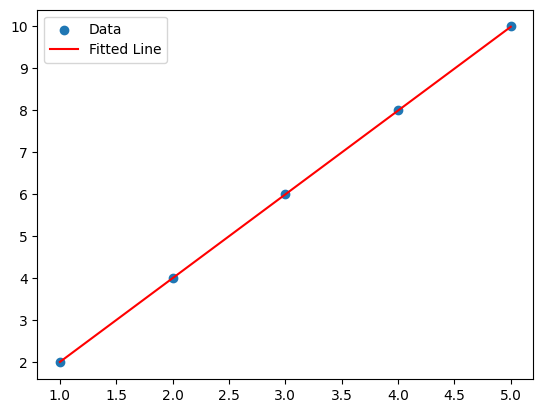

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Fake dataset
X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 6, 8, 10], dtype=float)  # perfect line: y = 2x

# Initialize parameters
m = 0.0  # slope
b = 0.0  # intercept
learning_rate = 0.01
iterations = 1000
n = len(X)

# Gradient descent loop
for _ in range(iterations):
    y_pred = m * X + b
    error = y - y_pred

    # Gradients
    dm = (-2/n) * np.sum(X * error)
    db = (-2/n) * np.sum(error)

    # Update parameters
    m -= learning_rate * dm
    b -= learning_rate * db

print(f"Final slope (m): {m:.4f}")
print(f"Final intercept (b): {b:.4f}")

# Plot results
plt.scatter(X, y, label="Data")
plt.plot(X, m*X + b, color="red", label="Fitted Line")
plt.legend()
plt.show()

## 4. Expected Result

Since the real relationship is $y = 2x$, gradient descent should find:

* $m \approx 2$
* $b \approx 0$

And the red line will match the blue data points.

---

# Gradient Descent for Multiple Features (Multivariable Linear Regression).


---

## 1. Problem Setup

For multiple features, the model is:

$$
\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b
$$

or in vector form:

$$
\hat{y} = Xw + b
$$

Where:

* $X$ = data matrix ($m \times n$, with $m$ samples and $n$ features)
* $w$ = weights (slopes for each feature)
* $b$ = bias (intercept)

Loss function (Mean Squared Error):

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^m \big( y_i - (X_i w + b) \big)^2
$$

---

## 2. Gradients

$$
\frac{\partial J}{\partial w} = -\frac{2}{m} X^T (y - \hat{y})
$$

$$
\frac{\partial J}{\partial b} = -\frac{2}{m} \sum (y - \hat{y})
$$

---

## 3. Python Implementation

In [3]:
import numpy as np

# Fake dataset (2 features)
# y = 3*x1 + 5*x2 + 10
X = np.array([
    [1, 2],
    [2, 1],
    [3, 4],
    [4, 3],
    [5, 5]
], dtype=float)

y = np.array([3*row[0] + 5*row[1] + 10 for row in X], dtype=float)

# Parameters
m, n = X.shape
weights = np.zeros(n)
bias = 0.0
learning_rate = 0.01
iterations = 1000

# Gradient descent loop
for _ in range(iterations):
    y_pred = X.dot(weights) + bias
    error = y - y_pred

    # Gradients
    dw = (-2/m) * X.T.dot(error)
    db = (-2/m) * np.sum(error)

    # Update
    weights -= learning_rate * dw
    bias -= learning_rate * db

print(f"Final weights: {weights}")
print(f"Final bias: {bias:.4f}")

# Test on new data
x_new = np.array([6, 2])
y_new = x_new.dot(weights) + bias
print(f"Prediction for {x_new}: {y_new:.2f}")

Final weights: [3.04840198 5.04775229]
Final bias: 9.6564
Prediction for [6 2]: 38.04



## 4. Expected Result

Since the true equation is:

$$
y = 3x_1 + 5x_2 + 10
$$

Gradient descent should converge to:

* `weights ≈ [3, 5]`
* `bias ≈ 10`

And predictions will match closely.

---

